In [9]:
%load_ext autoreload
%autoreload 2
    
import os
import sys
import pandas as pd
import xarray as xr
import numpy as np
from dask.distributed import Client
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm, Normalize
import warnings
warnings.filterwarnings('ignore')
from collections import defaultdict
from pathlib import Path
sys.path.append('/home/563/sc1326/repos/cdrmip_extremes')
from cdrmip_extremes.configs import data_dir, proc_dir
from cdrmip_extremes import processing, ext_freq, load_processed
from cdrmip_extremes.scenariomip import utils_ssp, plotting

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
client = Client(memory_limit=None,threads_per_worker=1,n_workers=28)

In [4]:
exceedances = load_processed.load_ext_data('ScenarioMIP',varnames=['cold_exceedances','heat_exceedances'])

Loading: /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/extremes/cold_exceedances/ACCESS-CM2/ssp126/ACCESS-CM2_ssp126_cold_exceedances.nc
Loading: /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/extremes/cold_exceedances/ACCESS-ESM1-5/ssp126/ACCESS-ESM1-5_ssp126_cold_exceedances.nc
Loading: /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/extremes/cold_exceedances/ACCESS-ESM1-5/ssp534-over/ACCESS-ESM1-5_ssp534-over_cold_exceedances.nc
Loading: /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/extremes/cold_exceedances/CESM2-WACCM/ssp126/CESM2-WACCM_ssp126_cold_exceedances.nc
Loading: /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/extremes/cold_exceedances/CESM2-WACCM/ssp534-over/CESM2-WACCM_ssp534-over_cold_exceedances.nc
Loading: /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/extremes/cold_exceedances/CNRM-ESM2-1/ssp534-over/CNRM-ESM2-1_ssp534-over_cold_exceedances.nc
Loading: /

In [5]:
exceedances

<xarray.DataTree>
Group: /
├── Group: /ACCESS-CM2
│   └── Group: /ACCESS-CM2/ssp126
│       ├── Group: /ACCESS-CM2/ssp126/cold_exceedances
│       │       Dimensions:  (period: 2, lat: 90, lon: 180)
│       │       Coordinates:
│       │         * period   (period) <U4 32B 'pre' 'post'
│       │         * lat      (lat) float64 720B -89.5 -87.49 -85.48 -83.47 ... 85.48 87.49 89.5
│       │         * lon      (lon) float64 1kB -179.5 -177.5 -175.5 -173.5 ... 175.5 177.5 179.5
│       │           extrema  <U4 16B ...
│       │       Data variables:
│       │           sigma1   (period, lat, lon) float64 259kB ...
│       │           sigma2   (period, lat, lon) float64 259kB ...
│       │           sigma3   (period, lat, lon) float64 259kB ...
│       └── Group: /ACCESS-CM2/ssp126/heat_exceedances
│               Dimensions:  (period: 2, lat: 90, lon: 180)
│               Coordinates:
│                 * period   (period) <U4 32B 'pre' 'post'
│                 * lat      (lat) float64 720B -89.5 -87.49 -85.48 -83.47 ... 85.48 87.49 89.5
│                 * lon      (lon) float64 1kB -179.5 -177.5 -175.5 -173.5 ... 175.5 177.5 179.5
│                   extrema  <U4 16B ...
│               Data variables:
│                   sigma1   (period, lat, lon) float64 259kB ...
│                   sigma2   (period, lat, lon) float64 259kB ...
│                   sigma3   (period, lat, lon) float64 259kB ...
├── Group: /ACCESS-ESM1-5
│   ├── Group: /ACCESS-ESM1-5/ssp126
│   │   ├── Group: /ACCESS-ESM1-5/ssp126/cold_exceedances
│   │   │       Dimensions:  (period: 2, lat: 90, lon: 180)
│   │   │       Coordinates:
│   │   │         * period   (period) <U4 32B 'pre' 'post'
│   │   │         * lat      (lat) float64 720B -89.5 -87.49 -85.48 -83.47 ... 85.48 87.49 89.5
│   │   │         * lon      (lon) float64 1kB -179.5 -177.5 -175.5 -173.5 ... 175.5 177.5 179.5
│   │   │           extrema  <U4 16B ...
│   │   │       Data variables:
│   │   │           sigma1   (period, lat, lon) float64 259kB ...
│   │   │           sigma2   (period, lat, lon) float64 259kB ...
│   │   │           sigma3   (period, lat, lon) float64 259kB ...
│   │   └── Group: /ACCESS-ESM1-5/ssp126/heat_exceedances
│   │           Dimensions:  (period: 2, lat: 90, lon: 180)
│   │           Coordinates:
│   │             * period   (period) <U4 32B 'pre' 'post'
│   │             * lat      (lat) float64 720B -89.5 -87.49 -85.48 -83.47 ... 85.48 87.49 89.5
│   │             * lon      (lon) float64 1kB -179.5 -177.5 -175.5 -173.5 ... 175.5 177.5 179.5
│   │               extrema  <U4 16B ...
│   │           Data variables:
│   │               sigma1   (period, lat, lon) float64 259kB ...
│   │               sigma2   (period, lat, lon) float64 259kB ...
│   │               sigma3   (period, lat, lon) float64 259kB ...
│   └── Group: /ACCESS-ESM1-5/ssp534-over
│       ├── Group: /ACCESS-ESM1-5/ssp534-over/cold_exceedances
│       │       Dimensions:  (period: 2, lat: 90, lon: 180)
│       │       Coordinates:
│       │         * period   (period) <U4 32B 'pre' 'post'
│       │         * lat      (lat) float64 720B -89.5 -87.49 -85.48 -83.47 ... 85.48 87.49 89.5
│       │         * lon      (lon) float64 1kB -179.5 -177.5 -175.5 -173.5 ... 175.5 177.5 179.5
│       │           extrema  <U4 16B ...
│       │       Data variables:
│       │           sigma1   (period, lat, lon) float64 259kB ...
│       │           sigma2   (period, lat, lon) float64 259kB ...
│       │           sigma3   (period, lat, lon) float64 259kB ...
│       └── Group: /ACCESS-ESM1-5/ssp534-over/heat_exceedances
│               Dimensions:  (period: 2, lat: 90, lon: 180)
│               Coordinates:
│                 * period   (period) <U4 32B 'pre' 'post'
│                 * lat      (lat) float64 720B -89.5 -87.49 -85.48 -83.47 ... 85.48 87.49 89.5
│                 * lon      (lon) float64 1kB -179.5 -177.5 -175.5 -173.5 ... 175.5 177.5 179.5
│                   extrema  <U4 16B ...
│               D

In [10]:
differences, agreement = utils_ssp.calc_gwl_differences(exceedances)

## Plot

In [6]:
def _get_ds(data, *keys):
    """Walk into a nested dict or DataTree using the given keys and return a Dataset."""
    node = data
    for k in keys:
        node = node[k]
    return node.ds if hasattr(node, 'ds') else node


def plot_ext_freq(ext_freq_data, differences, agreement, model, expt, varname, ext_type, model_name=None):
    """
    ext_freq_data : DataTree or nested dict { model: { expt: { varname: ds } } }
                    raw frequency data, ds has 'sigma1'/'sigma2'/'sigma3' variables
                    with dims including period, lat, lon
    differences   : DataTree or nested dict { model: { expt: { varname: ds } } }
                    precomputed ramp_down - ramp_up, ds has 'sigma1'/'sigma2'/'sigma3'
                    variables with dims including, lat, lon (no period dim)
    agreement     : DataTree or nested dict { expt: { varname: ds } }
                    ds has 'sigma1'/'sigma2'/'sigma3' variables with dims including
                    gwl, lat, lon (no model or branch dim)
    model, expt, varname : str, select which node to plot
    gwl             : the global warming level to select
    ext_type        : 'heat' or 'cold'
    model_name      : optional display name for the title (defaults to `model`)
    """
    if model_name is None:
        model_name = model

    exceedance = _get_ds(ext_freq_data, model, expt, varname)
    diff = _get_ds(differences, model, expt, varname)
    agreement_ds = _get_ds(agreement, expt, varname)

    # extract data to plot
    to_plot = {}
    thresholds = ['sigma1','sigma2','sigma3']
    for threshold in thresholds:
        ramp_up = exceedance[threshold].sel(period='pre')
        ramp_down = exceedance[threshold].sel(period='post')
        to_plot[threshold] = {'ramp_up':ramp_up,
                              'ramp_down':ramp_down,
                              'difference':diff[threshold]
                             }                             

    # set parameters based on ext_type
    if ext_type == 'heat':
        threshold_symbs = ['1$\sigma$','2$\sigma$','3$\sigma$']
        levels = np.linspace(0,100,11)
        levels_diff = np.linspace(-50,50,21)
        norm1 = BoundaryNorm(levels, ncolors=plt.cm.YlOrRd.N, clip=True)
        norm2 = BoundaryNorm(levels_diff, ncolors=plt.cm.RdBu_r.N, clip=True)
        cmap1 = 'YlOrRd'
        cmap2 = 'RdBu_r'
    elif ext_type == 'cold':
        threshold_symbs = ['-0.25$\sigma$','-0.5$\sigma$','-1$\sigma$']
        levels = np.linspace(0,60,25)
        levels_diff = np.linspace(-30,30,25)
        norm1 = BoundaryNorm(levels, ncolors=plt.cm.YlGnBu.N, clip=True)
        norm2 = BoundaryNorm(levels_diff, ncolors=plt.cm.RdBu.N, clip=True)
        cmap1 = 'YlGnBu'
        cmap2 = 'RdBu'

    fig, axes = plt.subplots(3,
                             3,
                             subplot_kw={"projection":ccrs.Robinson()},
                             figsize=(16,9),
                             sharey=True,
                            )
    cbar_kwargs = {"fraction": 0.06, "aspect": 25,
                    "label":"Frequency of Occurrence (% of years within window)",'orientation':'horizontal',
                    'location':'bottom','pad':0.04,
                   }
    cbar_kwargs_diff = {"fraction": 0.06, "aspect": 25,
                    "label":"Change in %",'orientation':'horizontal',
                    'location':'bottom','pad':0.04,
                   } 

    for row_index, threshold in enumerate(thresholds):
        for col_index, data in enumerate(list(to_plot[threshold].keys())):
            ax = axes[row_index,col_index]
            if data=='difference':
                norm=norm2
                cmap=cmap2
            else:
                norm=norm1
                cmap=cmap1
            ds = to_plot[threshold][data]
            lat, lon = ds.lat, ds.lon
            im = ax.pcolormesh(lon,lat,ds,
                           transform=ccrs.PlateCarree(),
                           cmap=cmap,
                           norm=norm
                          )
            ax.coastlines()
        axes[row_index, 0].annotate(threshold_symbs[row_index], xy=(-0.025, 0.5), xycoords="axes fraction",
                ha="right", va="center", fontsize=20, rotation=0,)

    # Add colorbars
    cbar_ax1 = fig.add_axes([0.057, -0.02, 0.6,0.025])
    cbar1 = fig.colorbar(
        plt.cm.ScalarMappable(norm=norm1, cmap=cmap1), 
        cax=cbar_ax1, 
        orientation='horizontal',
        label="% Years",
    )
    cbar1.ax.tick_params(labelsize=14)
    cbar1.set_label("Frequency of occurrence (% of years within window)", fontsize=16)

    cbar_ax2 = fig.add_axes([0.7, -0.02, 0.265,0.025])
    cbar2 = fig.colorbar(
        plt.cm.ScalarMappable(norm=norm2, cmap=cmap2), 
        cax=cbar_ax2, 
        orientation='horizontal',
        label="Change in %",
        extend='both',
    )
    if ext_type == 'cold':
        custom_ticks = [-30, -20, -10, 0, 10, 20, 30] 
        custom_labels = ['-30%', '-20%', '-10%', '0', '10%', '20%', '30%']
        cbar2.set_ticks(custom_ticks)
        cbar2.ax.set_xticklabels(custom_labels)

    cbar2.ax.tick_params(labelsize=14)
    cbar2.set_label("Change in frequency (difference in % of years)", fontsize=16)

    axes[0][0].set_title('Ramp Up',fontsize=20)
    axes[0][1].set_title('Ramp Down',fontsize=20)
    axes[0][2].set_title('Ramp Down - Ramp Up',fontsize=20)

    # plot stippling
    for index, threshold in enumerate(thresholds):
        lon = np.array(agreement_ds.lon)
        lat = np.array(agreement_ds.lat)
        hatch_data = agreement_ds[threshold]
        hatch_data, lon = add_cyclic_point(hatch_data,coord=lon)
        hatch_color = (0,0,0,0.5)

        contour = axes[index][2].contourf(
            lon,
            lat,
            hatch_data,
            transform=ccrs.PlateCarree(),
            levels=50,
            colors=[hatch_color],
            hatches=['/////'],
            alpha=0)

    column_labels = ['(a)', '(b)', '(c)']
    for col_index, label in enumerate(column_labels):
        axes[0, col_index].text(
            0.0, 1.02,
            label,
            transform=axes[0, col_index].transAxes,
            fontsize=20,
            va='bottom',
            ha='left',
        )

    fig.suptitle(f'{expt} {model_name} Change in {ext_type.capitalize()} Extreme Frequency at equivalent GWL',y=1.01,fontsize=25)
    fig.tight_layout()
    plt.show()

In [10]:
def _get_ds(data, *keys):
    """Walk into a nested dict or DataTree using the given keys and return a Dataset."""
    node = data
    for k in keys:
        node = node[k]
    return node.ds if hasattr(node, 'ds') else node


def plot_ext_freq_cont(ext_freq_data, differences, agreement, model, expt, varname, ext_type, model_name=None):
    """
    ext_freq_data : DataTree or nested dict { model: { expt: { varname: ds } } }
                    raw frequency data, ds has 'sigma1'/'sigma2'/'sigma3' variables
                    with dims including period, lat, lon
    differences   : DataTree or nested dict { model: { expt: { varname: ds } } }
                    precomputed ramp_down - ramp_up, ds has 'sigma1'/'sigma2'/'sigma3'
                    variables with dims including, lat, lon (no period dim)
    agreement     : DataTree or nested dict { expt: { varname: ds } }
                    ds has 'sigma1'/'sigma2'/'sigma3' variables with dims including
                    gwl, lat, lon (no model or branch dim)
    model, expt, varname : str, select which node to plot
    gwl             : the global warming level to select
    ext_type        : 'heat' or 'cold'
    model_name      : optional display name for the title (defaults to `model`)
    """
    if model_name is None:
        model_name = model

    exceedance = _get_ds(ext_freq_data, model, expt, varname)
    diff = _get_ds(differences, model, expt, varname)
    agreement_ds = _get_ds(agreement, expt, varname)

    # extract data to plot
    to_plot = {}
    thresholds = ['sigma1','sigma2','sigma3']
    for threshold in thresholds:
        ramp_up = exceedance[threshold].sel(period='pre')
        ramp_down = exceedance[threshold].sel(period='post')
        to_plot[threshold] = {'ramp_up':ramp_up,
                              'ramp_down':ramp_down,
                              'difference':diff[threshold]
                             }                             

    # set parameters based on ext_type
    if ext_type == 'heat':
        threshold_symbs = ['1$\sigma$','2$\sigma$','3$\sigma$']
        # levels = np.linspace(0,100,11)
        # levels_diff = np.linspace(-50,50,21)
        # norm1 = BoundaryNorm(levels, ncolors=plt.cm.YlOrRd.N, clip=True)
        # norm2 = BoundaryNorm(levels_diff, ncolors=plt.cm.RdBu_r.N, clip=True)
        vmin1,vmax1 = 0,100
        vmin2,vmax2 = -50,50
        cmap1 = 'YlOrRd'
        cmap2 = 'RdBu_r'
    elif ext_type == 'cold':
        threshold_symbs = ['-0.25$\sigma$','-0.5$\sigma$','-1$\sigma$']
        # levels = np.linspace(0,60,25)
        # levels_diff = np.linspace(-30,30,25)
        # norm1 = BoundaryNorm(levels, ncolors=plt.cm.YlGnBu.N, clip=True)
        # norm2 = BoundaryNorm(levels_diff, ncolors=plt.cm.RdBu.N, clip=True)
        vmin1,vmax1 = 0,60
        vmin2,vmax2 = -30,30
        cmap1 = 'YlGnBu'
        cmap2 = 'RdBu'



    norm1 = Normalize(vmin=vmin1, vmax=vmax1)
    norm2 = Normalize(vmin=vmin2, vmax=vmax2)

    fig, axes = plt.subplots(3,
                             3,
                             subplot_kw={"projection":ccrs.Robinson()},
                             figsize=(16,9),
                             sharey=True,
                            )
    cbar_kwargs = {"fraction": 0.06, "aspect": 25,
                    "label":"Frequency of Occurrence (% of years within window)",'orientation':'horizontal',
                    'location':'bottom','pad':0.04,
                   }
    cbar_kwargs_diff = {"fraction": 0.06, "aspect": 25,
                    "label":"Change in %",'orientation':'horizontal',
                    'location':'bottom','pad':0.04,
                   } 

    for row_index, threshold in enumerate(thresholds):
        for col_index, data in enumerate(list(to_plot[threshold].keys())):
            ax = axes[row_index,col_index]
            if data=='difference':
                # norm=norm2
                vmin,vmax=vmin2,vmax2
                cmap=cmap2
            else:
                # norm=norm1
                vmin,vmax=vmin1,vmax1
                cmap=cmap1
            ds = to_plot[threshold][data]
            lat, lon = ds.lat, ds.lon
            im = ax.pcolormesh(
                lon,
                lat,
                ds,
                transform=ccrs.PlateCarree(),
                cmap=cmap,
                # norm=norm,
                vmin=vmin,
                vmax=vmax,
            )
            ax.coastlines()
        axes[row_index, 0].annotate(threshold_symbs[row_index], xy=(-0.025, 0.5), xycoords="axes fraction",
                ha="right", va="center", fontsize=20, rotation=0,)

    # Add colorbars
    cbar_ax1 = fig.add_axes([0.057, -0.02, 0.6,0.025])
    cbar1 = fig.colorbar(
        plt.cm.ScalarMappable(norm=norm1, cmap=cmap1), 
        cax=cbar_ax1, 
        orientation='horizontal',
        label="% Years",
    )
    cbar1.ax.tick_params(labelsize=14)
    cbar1.set_label("Frequency of occurrence (% of years within window)", fontsize=16)

    cbar_ax2 = fig.add_axes([0.7, -0.02, 0.265,0.025])
    cbar2 = fig.colorbar(
        plt.cm.ScalarMappable(norm=norm2, cmap=cmap2), 
        cax=cbar_ax2, 
        orientation='horizontal',
        label="Change in %",
        extend='both',
    )
    if ext_type == 'cold':
        custom_ticks = [-30, -20, -10, 0, 10, 20, 30] 
        custom_labels = ['-30%', '-20%', '-10%', '0', '10%', '20%', '30%']
        cbar2.set_ticks(custom_ticks)
        cbar2.ax.set_xticklabels(custom_labels)

    cbar2.ax.tick_params(labelsize=14)
    cbar2.set_label("Change in frequency (difference in % of years)", fontsize=16)

    axes[0][0].set_title('Ramp Up',fontsize=20)
    axes[0][1].set_title('Ramp Down',fontsize=20)
    axes[0][2].set_title('Ramp Down - Ramp Up',fontsize=20)

    # plot stippling
    for index, threshold in enumerate(thresholds):
        lon = np.array(agreement_ds.lon)
        lat = np.array(agreement_ds.lat)
        hatch_data = agreement_ds[threshold]
        hatch_data, lon = add_cyclic_point(hatch_data,coord=lon)
        hatch_color = (0,0,0,0.5)

        contour = axes[index][2].contourf(
            lon,
            lat,
            hatch_data,
            transform=ccrs.PlateCarree(),
            levels=50,
            colors=[hatch_color],
            hatches=['/////'],
            alpha=0)

    column_labels = ['(a)', '(b)', '(c)']
    for col_index, label in enumerate(column_labels):
        axes[0, col_index].text(
            0.0, 1.02,
            label,
            transform=axes[0, col_index].transAxes,
            fontsize=20,
            va='bottom',
            ha='left',
        )

    fig.suptitle(f'{expt} {model_name} Change in {ext_type.capitalize()} Extreme Frequency at equivalent GWL',y=1.01,fontsize=25)
    fig.tight_layout()
    plt.show()

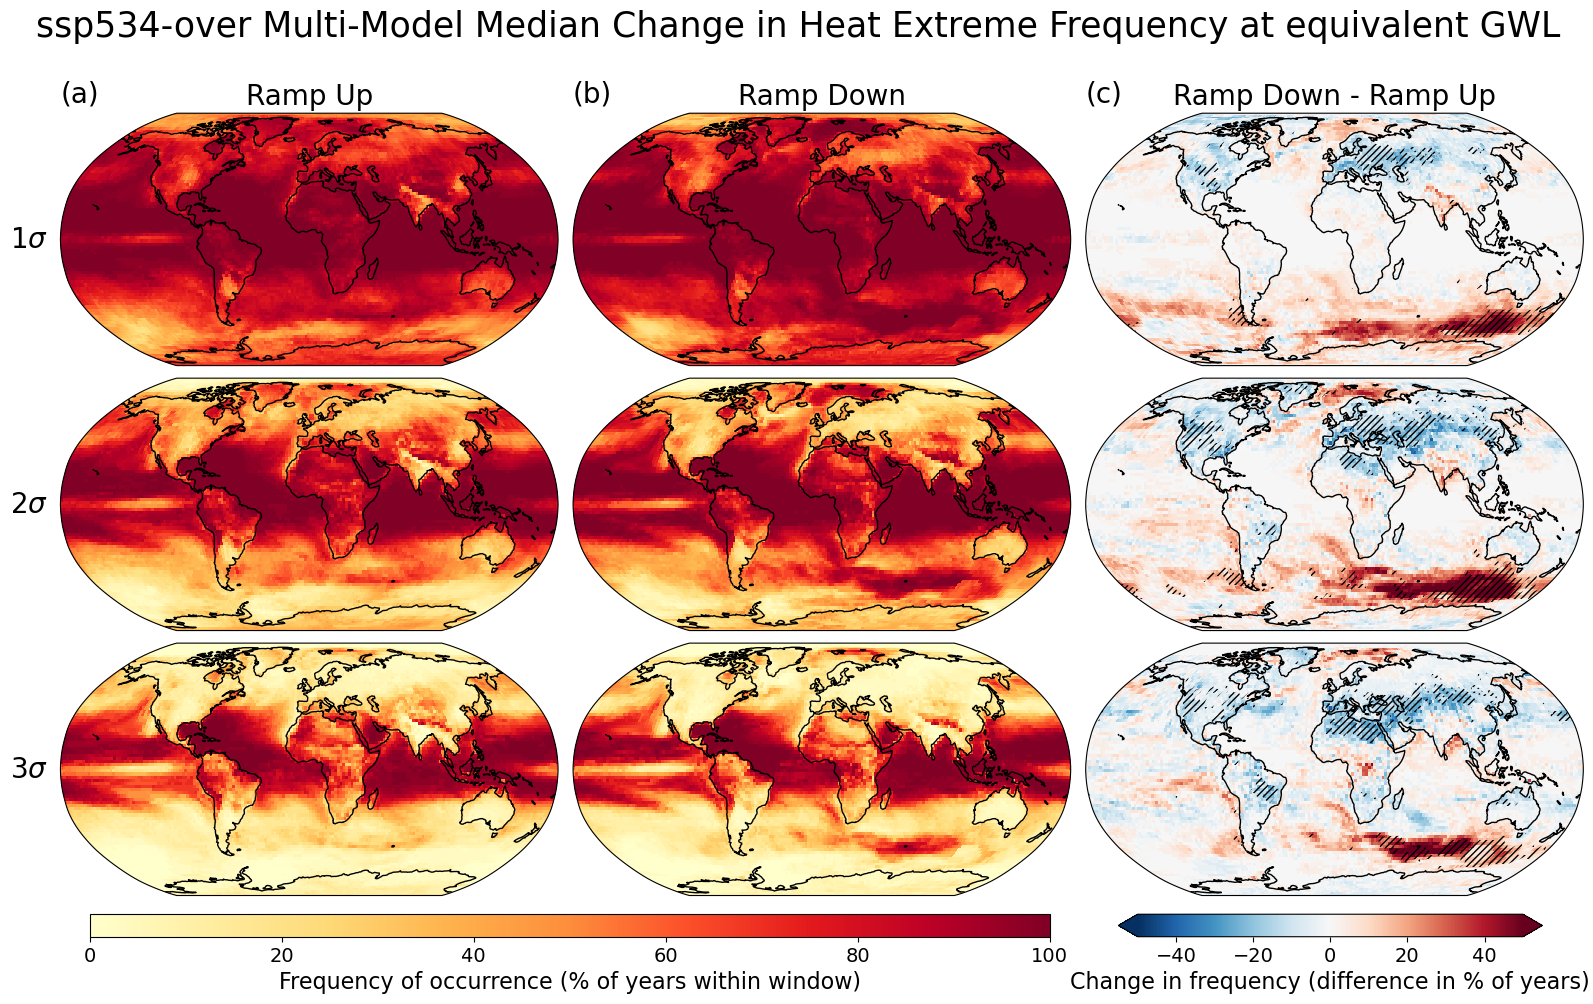

In [12]:
plotting.plot_ext_freq_cont(
    exceedances,
    differences,
    agreement,
    model='Multi-Model Median',
    expt='ssp534-over',
    varname='heat_exceedances',
    ext_type='heat',
)

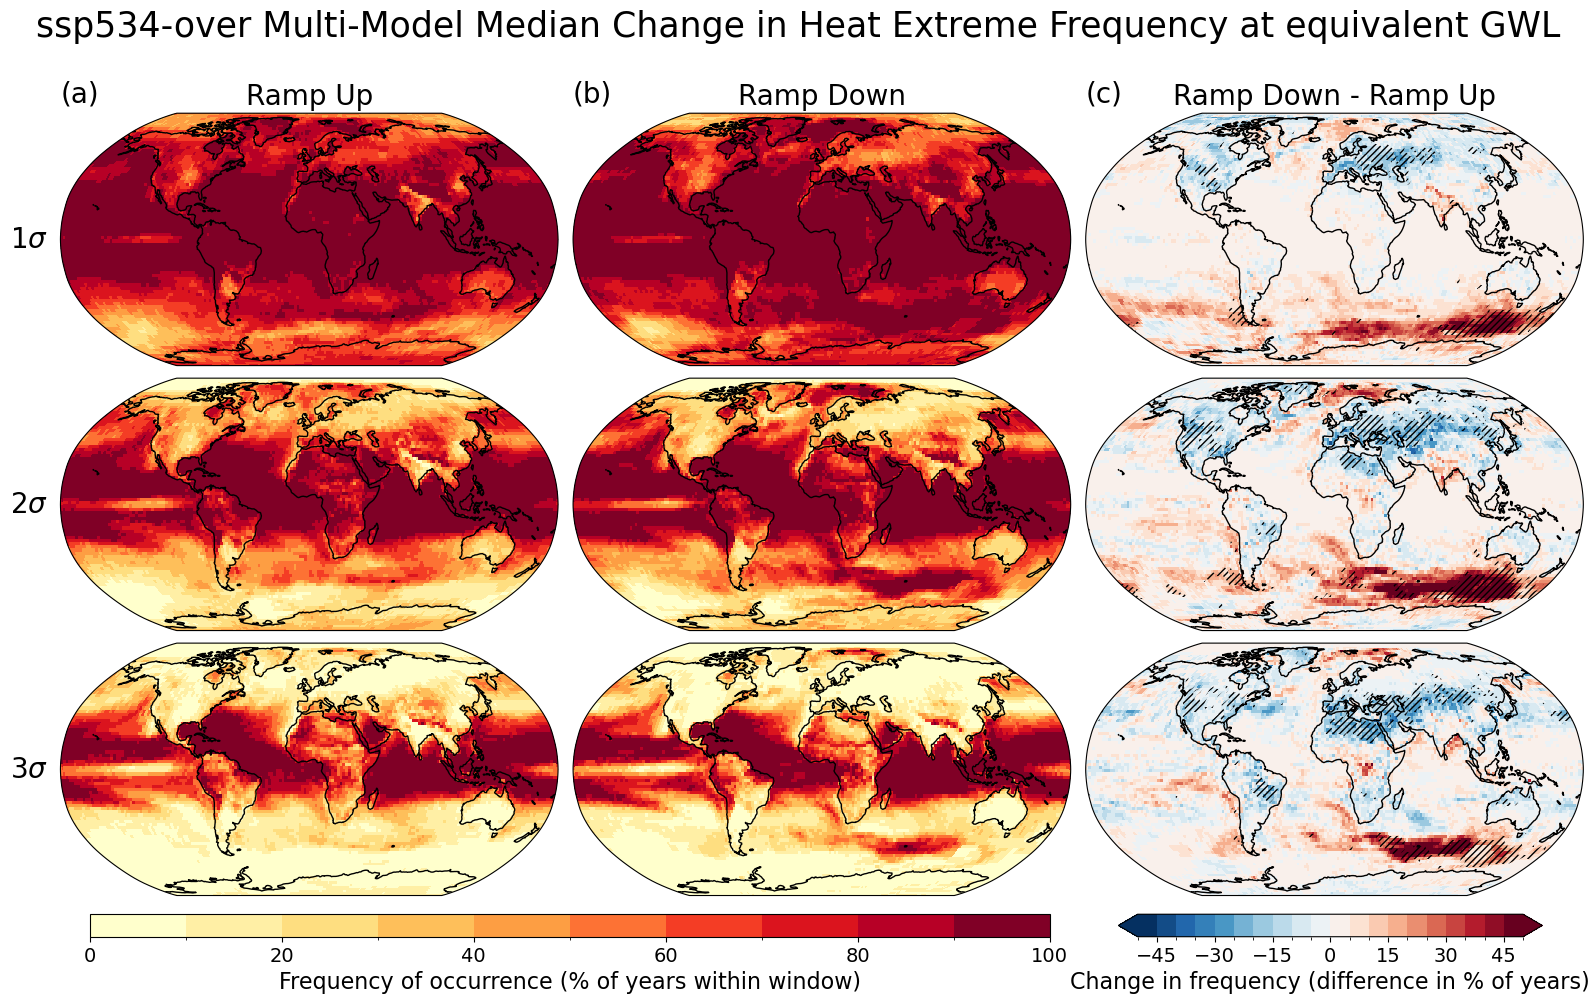

In [7]:
# agreement from a DataTree: expt/varname (no model level)
plot_ext_freq(
    exceedances,
    differences,
    agreement,
    model='Multi-Model Median',
    expt='ssp534-over',
    varname='heat_exceedances',
    ext_type='heat'
)

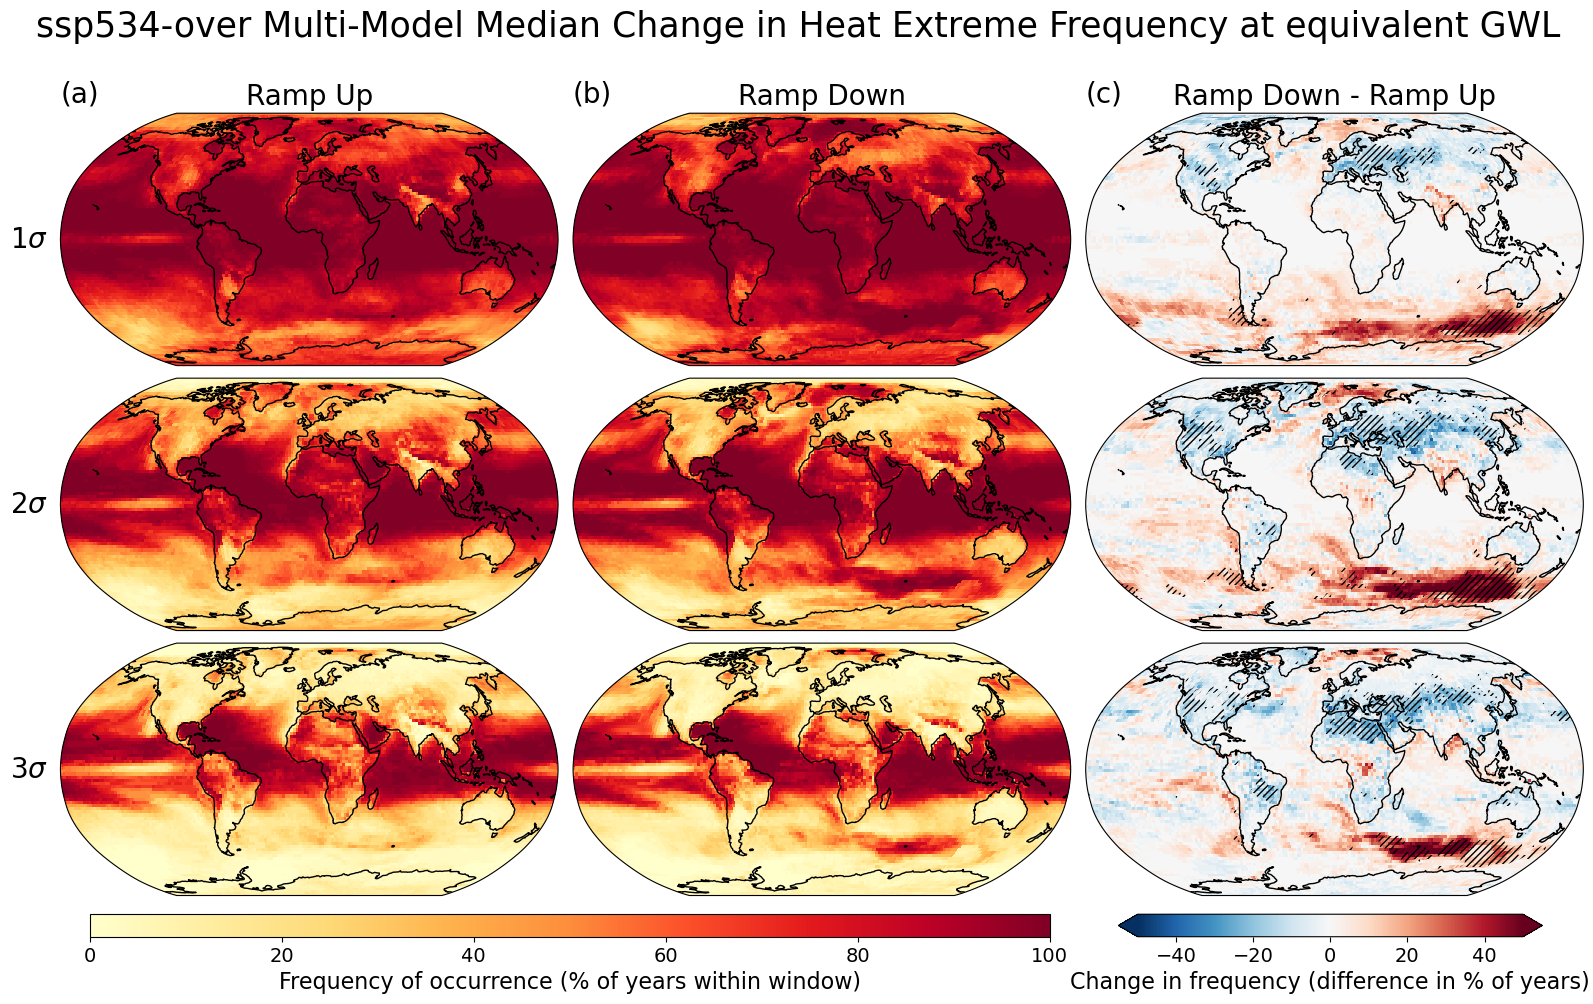

In [11]:
# agreement from a DataTree: expt/varname (no model level)
plot_ext_freq_cont(
    exceedances,
    differences,
    agreement,
    model='Multi-Model Median',
    expt='ssp534-over',
    varname='heat_exceedances',
    ext_type='heat'
)

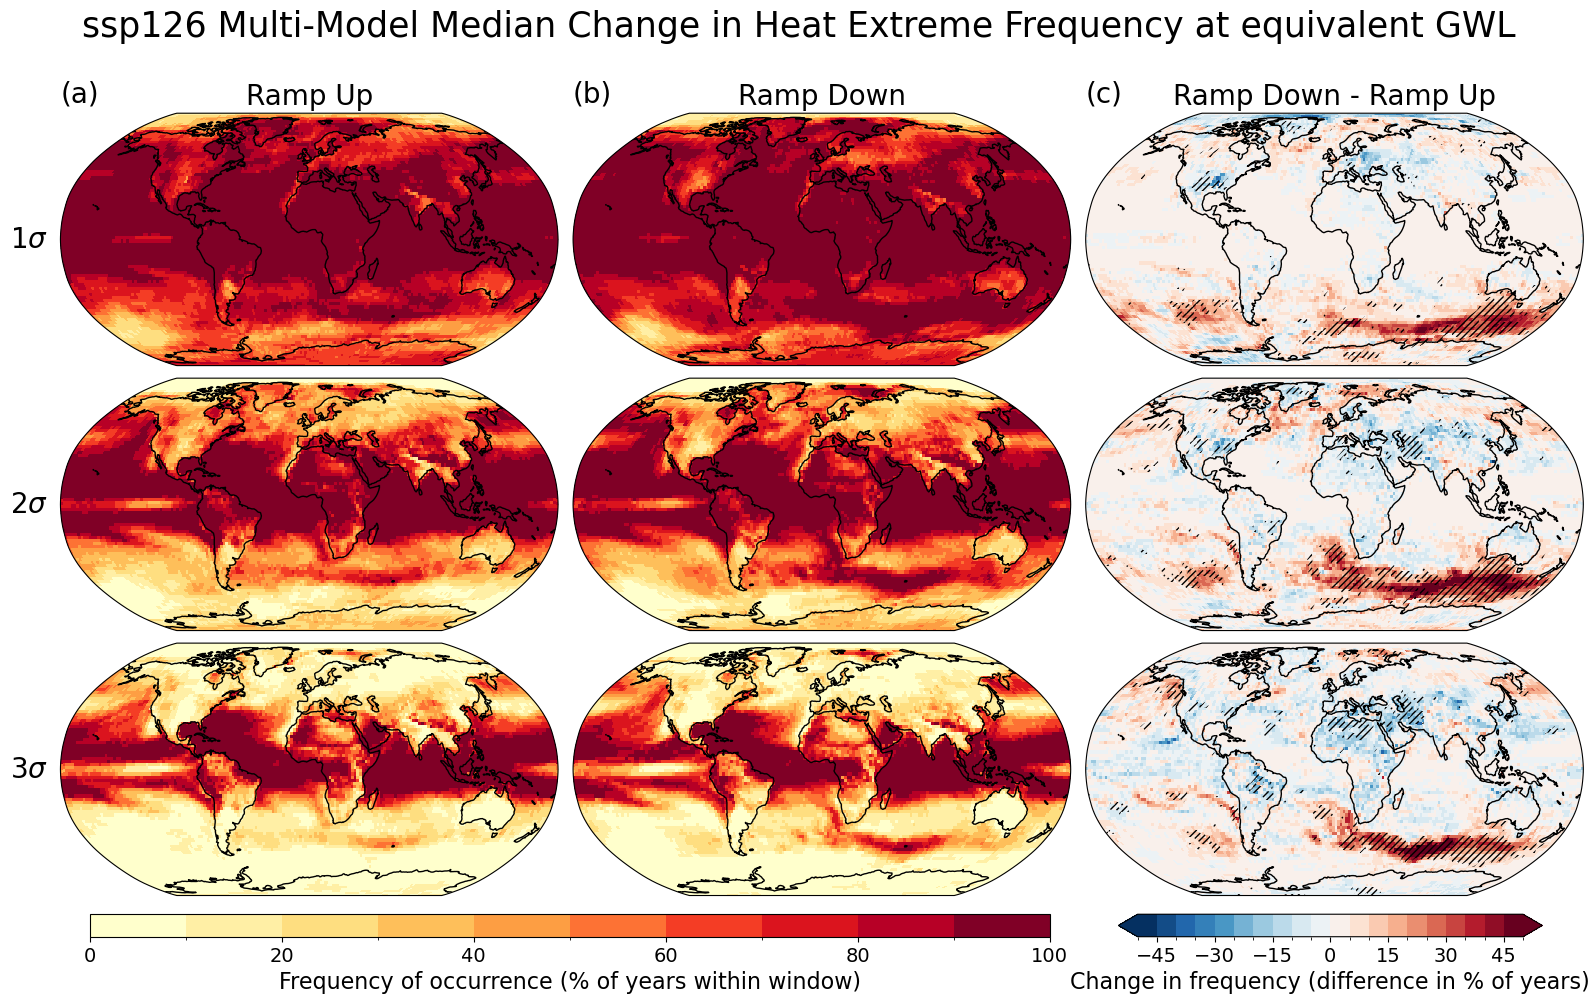

In [15]:
# agreement from a DataTree: expt/varname (no model level)
plot_ext_freq(
    exceedances,
    differences,
    agreement,
    model='Multi-Model Median',
    expt='ssp126',
    varname='heat_exceedances',
    ext_type='heat'
)

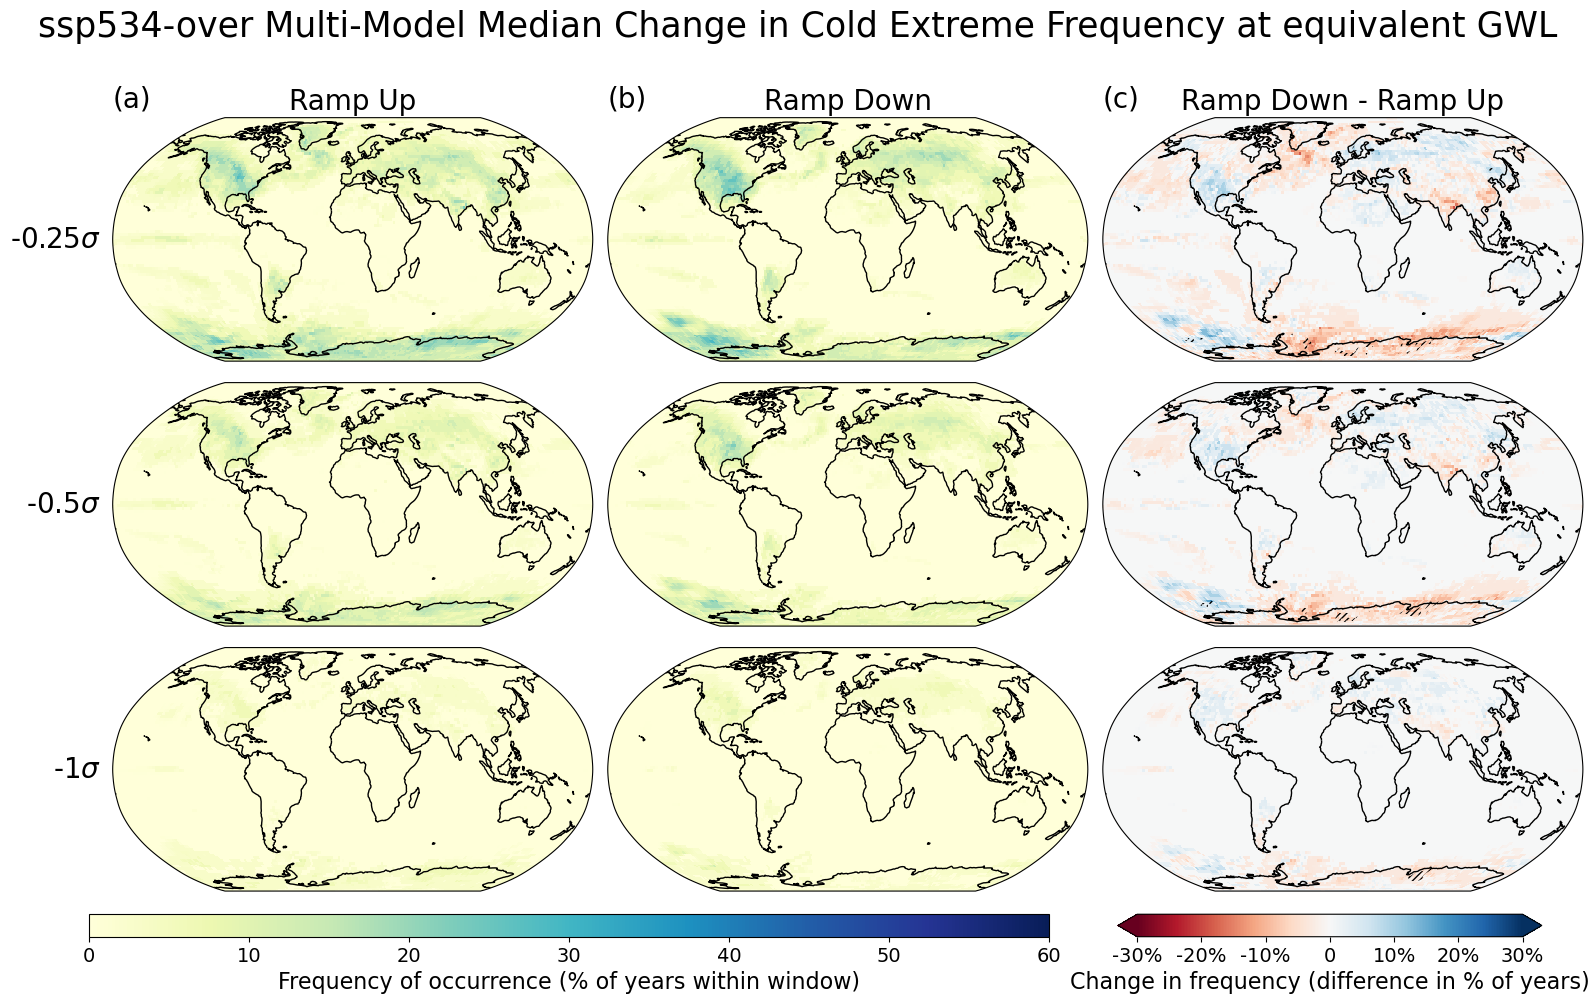

In [14]:
# agreement from a DataTree: expt/varname (no model level)
plot_ext_freq_cont(
    exceedances,
    differences,
    agreement,
    model='Multi-Model Median',
    expt='ssp534-over',
    varname='cold_exceedances',
    ext_type='cold'
)

In [12]:
def plot_model_diff(differences, ext_type, expt, varname,
                    threshold, levels, label, title):

    # define symbols for thresholds for title
    heat_symbs = {
        'sigma1': '1$\sigma$',
        'sigma2': '2$\sigma$',
        'sigma3': '3$\sigma$'
    }

    cold_symbs = {
        'sigma1': '-0.25$\sigma$',
        'sigma2': '-0.5$\sigma$',
        'sigma3': '-1$\sigma$'
    }

    if ext_type == 'heat':
        symb = heat_symbs[threshold]
        cmap = plt.cm.RdBu_r.copy()
        cmap.set_extremes(under='midnightblue', over='maroon')

    elif ext_type == 'cold':
        symb = cold_symbs[threshold]
        cmap = plt.cm.RdBu.copy()
        cmap.set_extremes(under='maroon', over='midnightblue')

    to_plot = {
        model: expt_dict[expt][varname][threshold]
        for model, expt_dict in differences.items()
        if expt in expt_dict
    }

    n_models = len(to_plot)

    # Choose a roughly square layout
    ncols = int(np.ceil(np.sqrt(n_models)))
    nrows = int(np.ceil(n_models / ncols))

    fig, axes = plt.subplots(
        nrows,
        ncols,
        subplot_kw={"projection": ccrs.Robinson()},
        figsize=(4.5 * ncols, 3.2 * nrows),
        sharey=True,
    )

    axes = np.atleast_1d(axes).flatten()

    cbar_kwargs = {
        "fraction": 0.02,
        "aspect": 20,
        "label": "% Years",
        "orientation": "horizontal",
        "location": "bottom",
        "pad": 0.01,
        "extend": "both",
    }

    norm = BoundaryNorm(levels, ncolors=cmap.N, clip=True)

    for model, ax in zip(to_plot.keys(), axes):
        ds = to_plot[model]

        im = ax.pcolormesh(
            ds.lon,
            ds.lat,
            ds,
            transform=ccrs.PlateCarree(),
            cmap=cmap,
            norm=norm,
        )

        ax.set_title(model, fontsize=16)
        ax.coastlines()

    # Hide unused axes
    for ax in axes[n_models:]:
        ax.set_visible(False)

    cbar = fig.colorbar(
        im,
        ax=axes[:n_models],
        **cbar_kwargs,
    )

    cbar.ax.tick_params(labelsize=14)
    cbar.set_label("Difference in % of years", fontsize=16)

    fig.text(
        0,
        0.95,
        label,
        fontsize=20,
        va='bottom',
        ha='left'
    )

    fig.suptitle(
        f"Change in frequency of {title}-level {ext_type} events at equivalent GWL {expt}",
        fontsize=24,
        y=0.99
    )

    fig.tight_layout()
    plt.show()

In [7]:
def plot_model_diff(differences, ext_type, expt, varname,
                    threshold, levels, label, title):
    heat_symbs = {
        'sigma1': '1$\sigma$',
        'sigma2': '2$\sigma$',
        'sigma3': '3$\sigma$'
    }
    cold_symbs = {
        'sigma1': '-0.25$\sigma$',
        'sigma2': '-0.5$\sigma$',
        'sigma3': '-1$\sigma$'
    }
    if ext_type == 'heat':
        symb = heat_symbs[threshold]
        cmap = plt.cm.RdBu_r.copy()
        cmap.set_extremes(under='midnightblue', over='maroon')
    elif ext_type == 'cold':
        symb = cold_symbs[threshold]
        cmap = plt.cm.RdBu.copy()
        cmap.set_extremes(under='maroon', over='midnightblue')

    to_plot = {
        model: expt_dict[expt][varname][threshold]
        for model, expt_dict in differences.items()
        if expt in expt_dict
    }
    n_models = len(to_plot)
    ncols = int(np.ceil(np.sqrt(n_models)))
    nrows = int(np.ceil(n_models / ncols))

    # constrained_layout reserves space for the colorbar properly,
    # instead of tight_layout (which is applied after and overrides it)
    fig, axes = plt.subplots(
        nrows,
        ncols,
        subplot_kw={"projection": ccrs.Robinson()},
        figsize=(4.5 * ncols, 3.2 * nrows + 1.2),  # extra height for cbar row
        sharey=True,
        constrained_layout=True,
    )
    axes = np.atleast_1d(axes).flatten()

    cbar_kwargs = {
        "fraction": 0.08,     # thicker bar (was 0.02)
        "aspect": 35,         # wider relative to thickness
        "shrink": 0.8,        # controls horizontal extent
        "label": "% Years",
        "orientation": "horizontal",
        "location": "bottom",
        "pad": 0.05,          # more gap from the maps
        "extend": "both",
    }

    norm = BoundaryNorm(levels, ncolors=cmap.N, clip=True)
    for model, ax in zip(to_plot.keys(), axes):
        ds = to_plot[model]
        im = ax.pcolormesh(
            ds.lon,
            ds.lat,
            ds,
            transform=ccrs.PlateCarree(),
            cmap=cmap,
            norm=norm,
        )
        ax.set_title(model, fontsize=16)
        ax.coastlines()

    for ax in axes[n_models:]:
        ax.set_visible(False)

    cbar = fig.colorbar(
        im,
        ax=axes[:n_models],
        **cbar_kwargs,
    )
    cbar.ax.tick_params(labelsize=14)
    cbar.set_label("Difference in % of years", fontsize=16)

    fig.text(0, 0.98, label, fontsize=20, va='bottom', ha='left')
    fig.suptitle(
        f"Change in frequency of {title}-level {ext_type} events at equivalent GWL {expt}",
        fontsize=24,
    )
    # NOTE: no fig.tight_layout() here — it conflicts with constrained_layout
    plt.show()

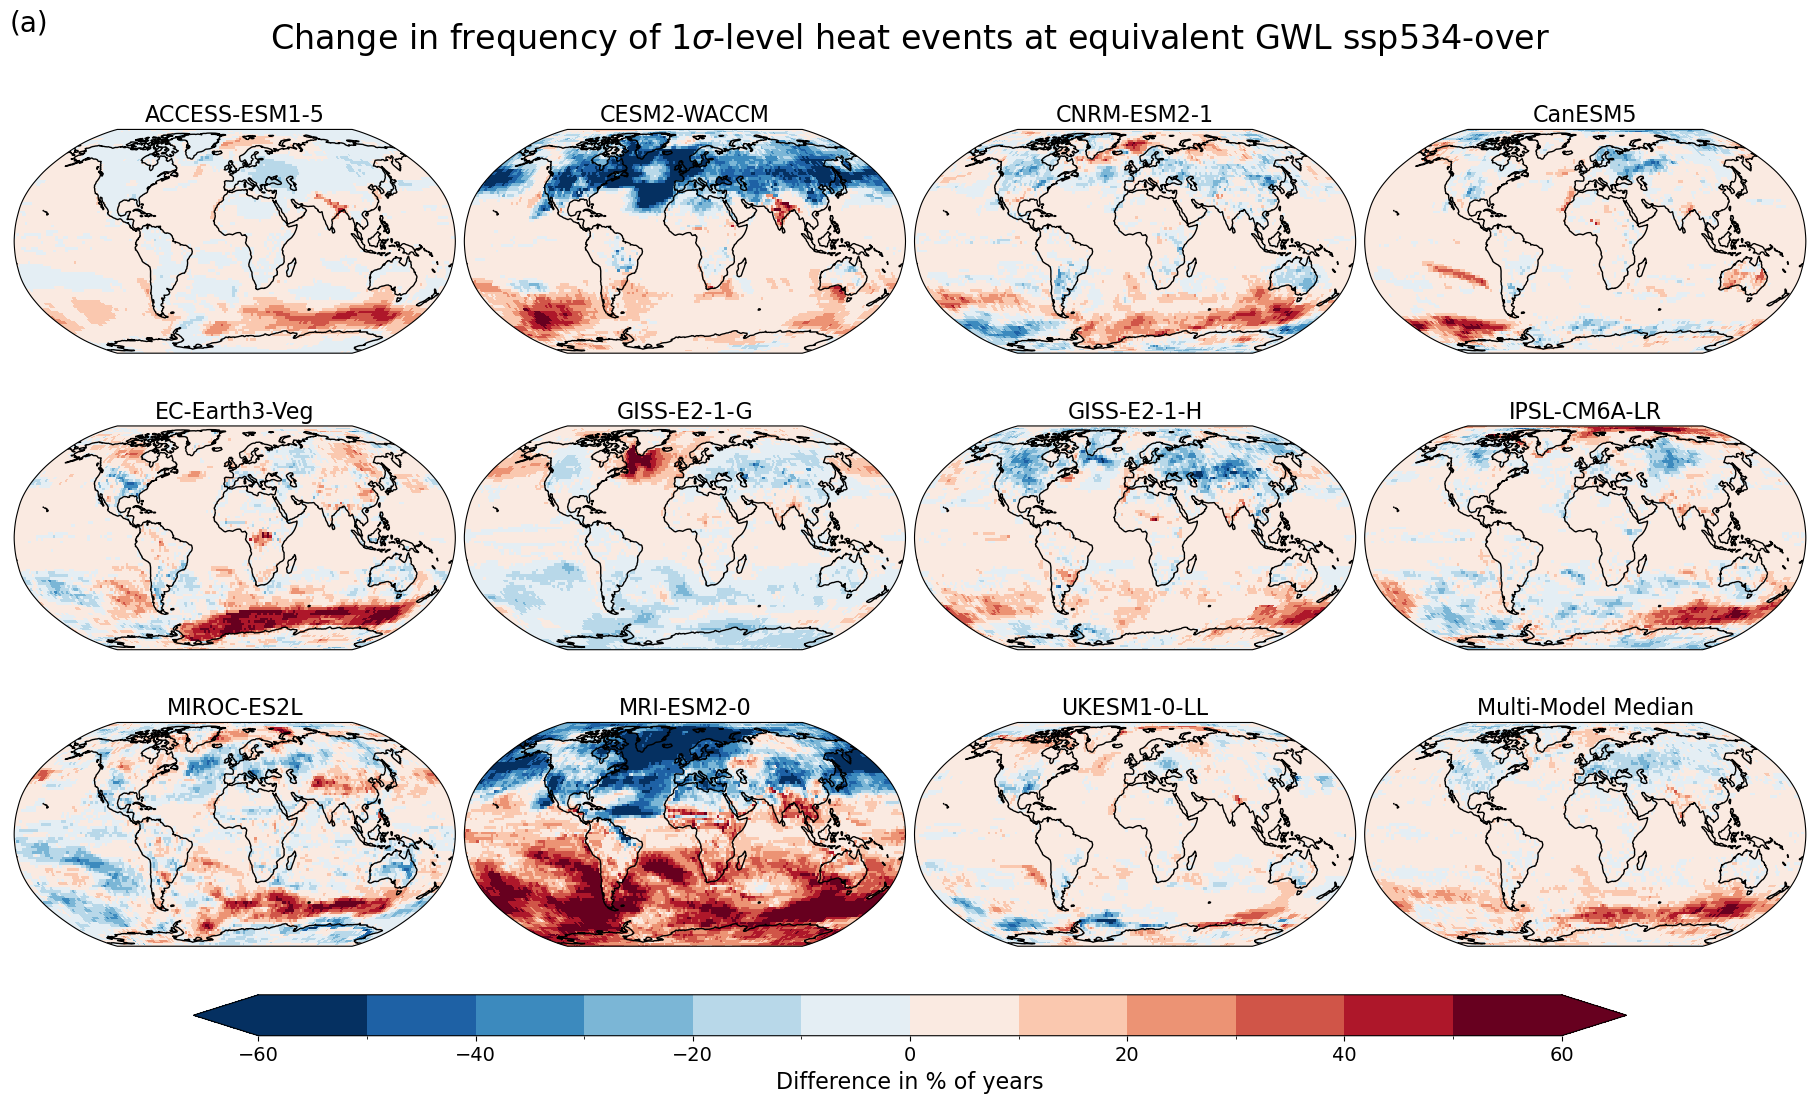

In [8]:
plot_model_diff(
    differences,
    'heat',
    'ssp534-over',
    'heat_exceedances',
    'sigma1',
    np.linspace(-60,60,13),
    '(a)'
    ,'1$\sigma$'
)

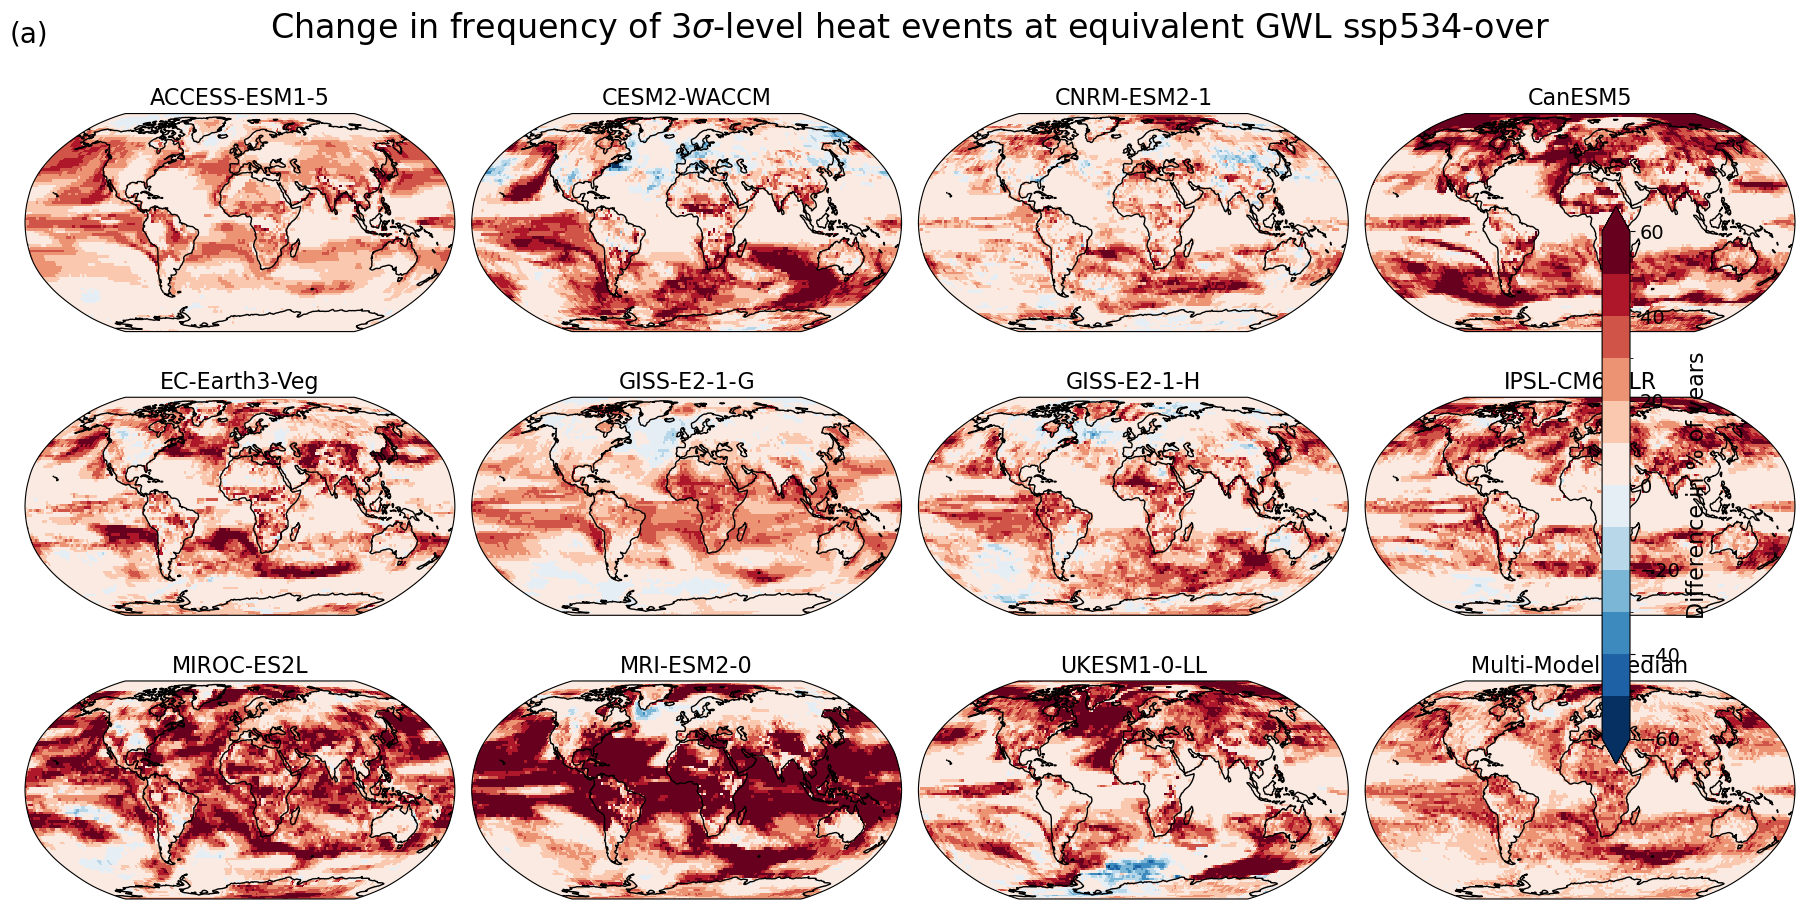

In [78]:
plot_model_diff(
    differences,
    'heat',
    'ssp534-over',
    'heat_exceedances',
    'sigma3',
    np.linspace(-60,60,13),
    '(a)'
    ,'3$\sigma$'
)